<a href="https://colab.research.google.com/github/NaderElmekawy/Telecom-Churn-Prediction-Retention-Business-Case/blob/main/NaderElmekawy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Company A | Churn prediction and retention business case
**Author:** NaderElmekawy  



## 1. Business question and market context
Can Company A reduce customer losses by prioritizing outreach to subscribers with a high predicted probability of churning 31–60 days after observation? McKinsey (2017) describes up to 15% churn reduction in selected telecom implementations, **not a guaranteed result for Company A**.

In [ ]:

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.inspection import permutation_importance

from google.colab import drive
drive.mount("/content/drive")

os.chdir("/content/drive/MyDrive/GCI World_202609/05. Final Assignment (due Nov 28)")

current_dir = Path(os.getcwd()) / "Final Assignment"

client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

for p in (client_path, record_path):
    print(f"{'OK' if p.is_file() else 'MISSING'}: {p}")

if not client_path.is_file() or not record_path.is_file():
    raise FileNotFoundError(
        "Client.csv or Record.csv was not found. "
        "Check that both files exist in Final Assignment/telecom."
    )

client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

df = record.merge(
    client,
    on="Customer_ID",
    validate="one_to_one"
)

print("\nDatasets loaded successfully!")
print("Client shape:", client.shape)
print("Record shape:", record.shape)
print("Merged shape:", df.shape)
print("Unique customers:", df["Customer_ID"].nunique())
print("Churn rate:", round(df["churn"].mean() * 100, 2), "%")

display(df.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK: /content/drive/.shortcut-targets-by-id/1ek_ShgcTnnMu9Am_3HvdGMYohoX5A9tv/GCI World_202609/05. Final Assignment (due Nov 28)/Final Assignment/telecom/Client.csv
OK: /content/drive/.shortcut-targets-by-id/1ek_ShgcTnnMu9Am_3HvdGMYohoX5A9tv/GCI World_202609/05. Final Assignment (due Nov 28)/Final Assignment/telecom/Record.csv

Datasets loaded successfully!
Client shape: (100000, 50)
Record shape: (100000, 51)
Merged shape: (100000, 100)
Unique customers: 100000
Churn rate: 49.56 %


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,O,0.0,I,U,U,U,U,U,Y,434.0


## 2. EDA and hypotheses
Target `churn` is explicitly defined as churn 31–60 days after the observation date. Explore customer care, handset age, revenue and usage. These are associations, not causal effects.

Missing fractions: numbcars            0.49366
dwllsize            0.38308
HHstatin            0.37923
ownrent             0.33706
dwlltype            0.31909
lor                 0.30190
income              0.25436
adults              0.23019
infobase            0.22079
hnd_webcap          0.10189
prizm_social_one    0.07388
avg6mou             0.02839
dtype: float64
Target balance:
 churn
0    0.50438
1    0.49562
Name: proportion, dtype: float64


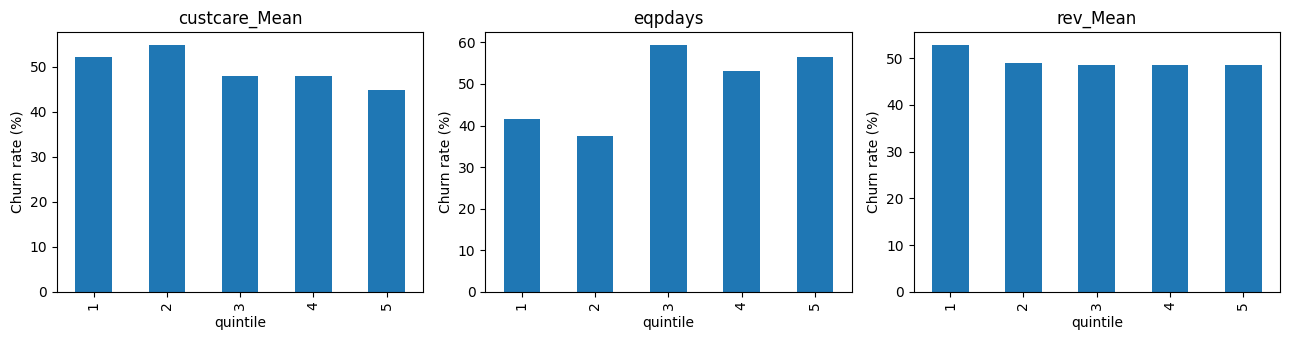

In [ ]:
print("Missing fractions:",df.isna().mean().sort_values(ascending=False).head(12))
print("Target balance:\n",df.churn.value_counts(normalize=True))
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
for ax,col in zip(axes,["custcare_Mean","eqpdays","rev_Mean"]):
 z=df[[col,"churn"]].dropna().copy();z["quintile"]=pd.qcut(z[col].rank(method="first"),5,labels=False)+1
 z.groupby("quintile").churn.mean().mul(100).plot.bar(ax=ax,title=col)
 ax.set_ylabel("Churn rate (%)")
plt.tight_layout();plt.show()

## 3. Modeling protocol
Use customer-level 75/25 stratified train/test split (seed 42). Restrict features to operational, billing and usage signals available at observation; exclude ID, target and sensitive demographic proxy variables. Missing numeric values are median-imputed inside each pipeline. Compare interpretable logistic regression against nonlinear gradient boosting. Primary metric: test ROC-AUC; also report average precision and precision/recall for top 20% highest-risk accounts. Random split is a feasibility check; time-split validation is required before deployment.

In [ ]:
features=['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'blck_vce_Mean', 'drop_blk_Mean', 'attempt_Mean', 'complete_Mean', 'custcare_Mean', 'months', 'uniqsubs', 'actvsubs', 'avgrev', 'avg3rev', 'avg6rev', 'avg3mou', 'avg6mou', 'hnd_price', 'eqpdays', 'phones', 'models', 'totrev']
X=df[features].replace([np.inf,-np.inf],np.nan);y=df.churn.astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
models={"Logistic regression":make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LogisticRegression(max_iter=450,random_state=42)),"Gradient boosting":make_pipeline(SimpleImputer(strategy="median"),HistGradientBoostingClassifier(max_iter=110,max_leaf_nodes=15,learning_rate=.08,random_state=42))}
results={};probabilities={}
for name,model in models.items():
 model.fit(X_train,y_train);p=model.predict_proba(X_test)[:,1];probabilities[name]=p
 selected=p>=np.quantile(p,.8)
 results[name]={"ROC-AUC":roc_auc_score(y_test,p),"Average precision":average_precision_score(y_test,p),"Top-20% precision":y_test[selected].mean(),"Top-20% recall":y_test[selected].sum()/y_test.sum()}
print(pd.DataFrame(results).T.round(4))
best=max(results,key=lambda k:results[k]["ROC-AUC"]);print("Selected:",best)

                     ROC-AUC  Average precision  Top-20% precision  \
Logistic regression   0.6028             0.5780             0.6104   
Gradient boosting     0.6742             0.6604             0.7100   

                     Top-20% recall  
Logistic regression          0.2463  
Gradient boosting            0.2865  
Selected: Gradient boosting


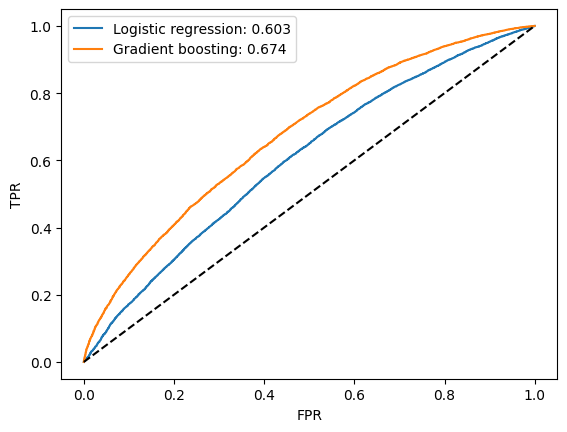

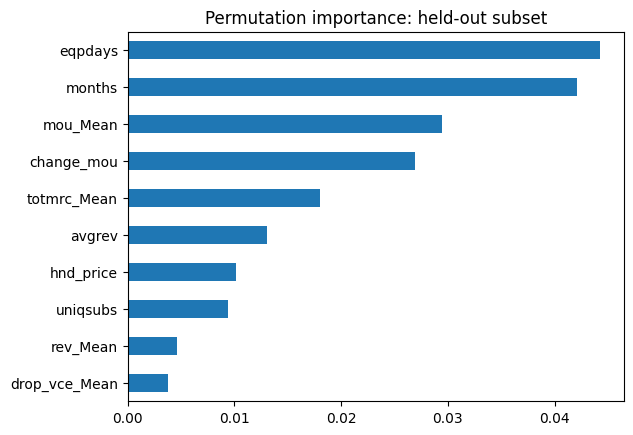

In [ ]:
for name,p in probabilities.items():
 fpr,tpr,_=roc_curve(y_test,p);plt.plot(fpr,tpr,label=f"{name}: {results[name]['ROC-AUC']:.3f}")
plt.plot([0,1],[0,1],"k--");plt.xlabel("FPR");plt.ylabel("TPR");plt.legend();plt.show()
subset=X_test.sample(n=3500,random_state=42)
pi=permutation_importance(models[best],subset,y_test.loc[subset.index],n_repeats=2,random_state=42,scoring="roc_auc")
pd.Series(pi.importances_mean,index=features).nlargest(10).sort_values().plot.barh(title="Permutation importance: held-out subset");plt.show()

## 4. Retention campaign and financial sensitivity
**Decision rule:** score all eligible customers; contact the highest-risk 20%. Use a randomized no-contact control group to measure *incremental* saves. Predictions do not demonstrate treatment effectiveness. Below assumptions are illustrative: 10% of predicted churners are incrementally retained, 3 months of preserved revenue, 50% contribution margin, 2 currency units per contact, 15 units per saved account. Currency is unspecified in source data; figures are **dataset monetary units**, not confirmed USD.

In [ ]:
chosen=results[best]["Top-20% precision"];contacted=int(len(df)*.2);would_churn=contacted*chosen
monthly_revenue=df.rev_Mean.clip(lower=0).mean()
def case(save_rate=.10,margin=.50,months=3,contact_cost=2,offer_cost=15):
 saved=would_churn*save_rate
 gross=saved*monthly_revenue*months*margin
 cost=contacted*contact_cost+saved*offer_cost
 return {"contacted":contacted,"would_churn_predicted":round(would_churn),"saved_assumed":round(saved),"gross_contribution":round(gross),"campaign_cost":round(cost),"net_contribution":round(gross-cost)}
print("Base case:",case())
print("Sensitivity:",pd.DataFrame({f"save_{int(rate*100)}%":case(save_rate=rate) for rate in [.05,.10,.15]}).T)

Base case: {'contacted': 20000, 'would_churn_predicted': 14200, 'saved_assumed': 1420, 'gross_contribution': 125074, 'campaign_cost': 61300, 'net_contribution': 63774}
Sensitivity:           contacted  would_churn_predicted  saved_assumed  gross_contribution  \
save_5%       20000                  14200            710               62537   
save_10%      20000                  14200           1420              125074   
save_15%      20000                  14200           2130              187611   

          campaign_cost  net_contribution  
save_5%           50650             11887  
save_10%          61300             63774  
save_15%          71950            115661  


## 5. Proposed pilot and guardrails
- Run a 6–8 week pilot with high-risk eligible customers randomized to outreach versus business-as-usual; measure 31–60 day churn and net incremental contribution.
- Tailor actions to observed problems: service troubleshooting, billing clarification, or contract/value-plan support. Avoid claiming a feature *causes* churn.
- Privacy: avoid sensitive demographic columns, restrict access, and check performance across approved groups.
- Monitor drift and recalibrate with temporally held-out data; account for treatment costs and campaign capacity.
